# 04 - End to end: FoldRescue predictions -> Loopwise batch -> plate map

> **This notebook uses a labelled stand-in, not FoldRescue.** The upstream
> FoldRescue model is not installed here, so `SyntheticFoldRescueModel` plays
> its part: a seeded simulator with a plausible structure-activity
> relationship. Everything about the *integration* is real -- the adapter, the
> budget arithmetic, the plate map. The *numbers* are simulated and are not
> predictions about GLB1. The last section shows the one-line change to point
> it at the real model.

## The biology

Some genetic diseases are not caused by a missing protein but by a
**misfolded** one. The gene is transcribed, the protein is made, and then the
cell's quality-control machinery sees a shape it does not recognize and
destroys it. The enzyme never reaches the compartment where it does its job.

**GM1 gangliosidosis** works this way. Mutations in *GLB1* destabilize
beta-galactosidase -- the lysosomal enzyme that breaks down GM1 ganglioside, a
lipid abundant in neuronal membranes. The misfolded enzyme is degraded before
it reaches the lysosome, GM1 accumulates, and neurons die. It is a
devastating, usually infantile disease.

A **pharmacological chaperone** is a small molecule that binds the unstable
protein and holds it in the right shape long enough to pass quality control and
reach the lysosome. Enough enzyme arrives to clear the substrate. The appeal is
that it rescues the patient's *own* enzyme -- no gene therapy, no enzyme
infusion -- and some chaperones cross the blood-brain barrier, which matters
when the disease is neurological.

## Why this is a Loopwise problem

- The candidate space is large (thousands of compounds).
- The readout is a cell-based enzyme-activity assay: days per round.
- The genuine rescue rate is low -- commonly under 1%.
- You can run a few hundred compounds a quarter.

A few thousand candidates, 96 wells, and a model that is wrong in ways you will
only discover by measuring the right things. That is exactly the regime where
*which* compounds you pick dominates how fast you learn.

In [1]:
import sys
from pathlib import Path

# Figures and tables land in results/ so the committed notebooks and the README
# reference the same files.
ROOT = Path.cwd()
if not (ROOT / "loopwise").exists():
    ROOT = ROOT.parent
FIGDIR = ROOT / "results" / "figures"
TABDIR = ROOT / "results" / "tables"
FIGDIR.mkdir(parents=True, exist_ok=True)
TABDIR.mkdir(parents=True, exist_ok=True)
print("loopwise", __import__("loopwise").__version__, "| figures ->", FIGDIR)

loopwise 0.1.0 | figures -> /home/user/loopwise/results/figures


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from loopwise.contrib.foldrescue import (
    FOLDRESCUE_PROTOCOL,
    FoldRescueAdapter,
    SyntheticFoldRescueModel,
    foldrescue_campaign,
)
from loopwise.plate import render_plate_map

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print("FoldRescue models must expose one of:", FOLDRESCUE_PROTOCOL["one_of"])
print("optionally:", FOLDRESCUE_PROTOCOL["optional"])

FoldRescue models must expose one of: ('sample', 'predict_proba', 'predict_rescue', 'predict')
optionally: ('fit', 'feature_names', 'n_bootstrap_members')


## The candidate pool

Two features of this pool mirror a real chaperone screen:

1. **Scaffold clustering.** Compounds come from 15 chemical series, so the top
   predictions cluster -- which is what makes a diversity constraint earn its
   keep.
2. **A non-monotone optimum.** Rescue depends on binding affinity through an
   inverted U: bind too weakly and nothing happens; bind too tightly and you
   *inhibit* the enzyme you meant to rescue. This is a real and well-known
   trade-off for iminosugar chaperones such as those explored for GM1 and
   Fabry disease. A model that assumes "more binding is better" gets the top of
   its ranking exactly wrong -- a realistic failure for an active strategy to
   recover from.

Compounds also carry an **acquisition cost**: about 20% are bespoke syntheses
at $300-900, the rest library compounds at $15-60.

In [3]:
pool, info = SyntheticFoldRescueModel.make_glb1_like_pool(
    n_items=3000, n_features=24, rescue_rate=0.03, n_scaffolds=15, seed=0
)
print({k: v for k, v in info.items() if k != "feature_cols"})
pool[["compound_id", "scaffold", "acquisition_cost_usd", "rescues_folding"]].head()

{'dataset': 'synthetic GLB1-like chaperone pool (NOT real data)', 'n_compounds': 3000, 'n_rescuers': 90, 'rescue_rate': 0.03, 'n_scaffolds': 15, 'structure': 'rescue depends on an inverted-U in pharmacophore_0 (binding affinity: too weak does nothing, too strong inhibits) plus linear terms in pharmacophore_1..3'}


,compound_id,scaffold,acquisition_cost_usd,rescues_folding
0,GLB1-00000,7,627.84,0
1,GLB1-00001,14,46.14,0
2,GLB1-00002,14,36.03,0
3,GLB1-00003,1,33.81,0
4,GLB1-00004,11,24.84,0


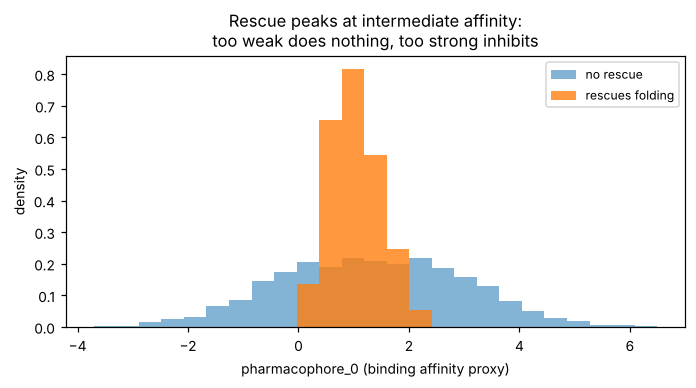

In [4]:
# The inverted-U, visible: rescuers sit at intermediate binding affinity.
fig, ax = plt.subplots(figsize=(6.4, 3.6))
bins = np.linspace(pool["pharmacophore_0"].min(), pool["pharmacophore_0"].max(), 26)
ax.hist(pool.loc[pool["rescues_folding"] == 0, "pharmacophore_0"], bins=bins,
        alpha=0.55, label="no rescue", density=True)
ax.hist(pool.loc[pool["rescues_folding"] == 1, "pharmacophore_0"], bins=bins,
        alpha=0.8, label="rescues folding", density=True)
ax.set_xlabel("pharmacophore_0 (binding affinity proxy)")
ax.set_ylabel("density")
ax.set_title("Rescue peaks at intermediate affinity:\ntoo weak does nothing, too strong inhibits")
ax.legend(fontsize=8)
fig.tight_layout()
FIGDIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGDIR / "04_inverted_u_affinity.png", dpi=150, bbox_inches="tight")

## The adapter

FoldRescue supplies the **model**; Loopwise supplies the **selection**. The
adapter translates, and reports how it obtained uncertainty -- which is worth
printing, because the answer determines which policies are even available.

In [5]:
model = SyntheticFoldRescueModel(random_state=0)
adapter = FoldRescueAdapter(model, refit=True)
print("uncertainty mode:", adapter.uncertainty_mode)

uncertainty mode: native-sampling(sample)


`native-sampling(sample)` means the model exposes its own `sample()` method, so
Loopwise uses the model's own posterior rather than approximating one. The
fallbacks, in order:

| What the model exposes | How uncertainty is obtained |
| --- | --- |
| `sample(X, n)` | used directly -- the model's own posterior |
| `predict_proba` + `fit` | bootstrap ensemble (refit on resamples) |
| `predict_proba` only, frozen | none; information-seeking policies **raise** |

That last row is deliberate. A frozen point model cannot express uncertainty,
so BALD scores would all be exactly zero and the "selected" batch would be
whatever the tie-break produced. Loopwise refuses instead of quietly becoming
random sampling.

## The campaign

The defaults in `foldrescue_campaign` encode what a cell-based rescue assay
actually costs, rather than what is convenient:

- **Duplicates.** A single well of a cell-based enzyme-activity assay is not a
  measurement you would act on. So a 96-well budget buys **48 compounds**, not
  96 -- the replicate policy does that arithmetic.
- **$450 per plate.** Cells, substrate, detection reagent and a technician's
  day. For library compounds this dominates per-compound cost, which is why the
  plate term is not optional.
- **Per-compound acquisition cost** from the pool, so a $600 bespoke synthesis
  and a $30 library compound do not compete equally for the same well.
- **A 96-well plate with controls**: wild-type enzyme (positive) and untreated
  mutant (negative) on every plate. A rescue assay without them is
  uninterpretable.

We seed with 150 already-measured compounds -- the pilot screen a project
typically has before anyone builds a model.

In [6]:
truth = dict(zip(pool["compound_id"], pool["rescues_folding"], strict=True))
blind = pool.drop(columns=["rescues_folding"])
pilot_ids = list(blind["compound_id"][:150])
pilot = {i: truth[i] for i in pilot_ids}
print(f"pilot screen: {len(pilot)} compounds, {sum(pilot.values())} rescuers "
      f"({np.mean(list(pilot.values())):.1%})")

campaign = foldrescue_campaign(
    blind,
    model=model,
    budget=96,
    policy="hybrid",
    feature_cols=info["feature_cols"],
    cost_col="acquisition_cost_usd",
    n_replicates=2,
    plate_fixed_cost=450.0,
    n_rounds_planned=5,
    initial_labels=pilot,
    seed=0,
)
print()
print(campaign)
print(campaign.cost_model.describe())

pilot screen: 150 compounds, 3 rescuers (2.0%)

Campaign(pool=3000, labeled=150, rounds_done=0, policy='hybrid', budget=96, model='FoldRescue[SyntheticFoldRescueModel]')
Acquisition column 'acquisition_cost_usd' per compound; 450.00 USD per plate started; no currency cap; 2 replicate(s) per compound (counted against the well budget).


In [7]:
batch = campaign.select()
print(batch.explain())

Round 1: 48 compound(s) selected by policy 'hybrid'.
Selecting 48 compound(s); binding constraint: well budget.
Requested budget 96; well budget 96; 80 usable wells per plate.
Estimated cost: 48 compounds in 96 wells on 2 plate(s): 6,670.45 acquisition + 900.00 plate = 7,570.45 USD
2 replicates per compound count against the budget, so a 96-well budget buys 48 compounds (96 wells).
Cost: 48 compounds in 96 wells on 2 plate(s): 6,670.45 acquisition + 900.00 plate = 7,570.45 USD
96-well (8x12 = 96 wells): 8 positive + 8 negative control wells, edge ring in use, 80 wells available for samples.
96 sample wells across 2 plate(s); controls intact: True.
Edge wells are 25% of available sample wells; highest-score stratum edge enrichment vs chance 0.667 (balanced). With 96 samples in 4 strata this ratio is coarse -- one well either way moves it noticeably.


96 wells, 2 replicates each, 48 compounds -- and the cost breakdown separates
the acquisition spend from the plate overhead, so you can see which is actually
binding.

### Why each compound was chosen

In [8]:
cols = ["compound_id", "rank", "posterior_mean", "posterior_std",
        "acquisition_cost_usd", "alpha", "reason"]
batch.frame[cols].head(6)

,compound_id,rank,posterior_mean,posterior_std,acquisition_cost_usd,alpha,reason
817,GLB1-00817,1,0.356667,0.387857,750.05,0.4,rank 1/48 by 0.40*exploit + 0.60*bald (exploit...
1204,GLB1-01204,2,0.290556,0.395876,34.05,0.4,rank 2/48 by 0.40*exploit + 0.60*bald (exploit...
2653,GLB1-02653,3,0.297222,0.388806,18.28,0.4,rank 3/48 by 0.40*exploit + 0.60*bald (exploit...
2161,GLB1-02161,4,0.298889,0.384766,45.81,0.4,rank 4/48 by 0.40*exploit + 0.60*bald (exploit...
2464,GLB1-02464,5,0.272222,0.405832,33.76,0.4,rank 5/48 by 0.40*exploit + 0.60*bald (exploit...
2990,GLB1-02990,6,0.297778,0.378005,45.58,0.4,rank 6/48 by 0.40*exploit + 0.60*bald (exploit...


## The plate map

This is the artifact that goes to the bench.

In [9]:
layout = batch.plate_layout
print(layout.summary())
layout.to_grid(0, "content_type").iloc[:, :6]

96-well (8x12 = 96 wells): 8 positive + 8 negative control wells, edge ring in use, 80 wells available for samples.
96 sample wells across 2 plate(s); controls intact: True.
Edge wells are 25% of available sample wells; highest-score stratum edge enrichment vs chance 0.667 (balanced). With 96 samples in 4 strata this ratio is coarse -- one well either way moves it noticeably.


,1,2,3,4,5,6
A,negative_control,empty,sample,sample,empty,sample
B,negative_control,empty,sample,empty,sample,sample
C,negative_control,empty,sample,empty,sample,empty
D,negative_control,empty,sample,sample,sample,sample
E,negative_control,sample,empty,sample,sample,sample
F,negative_control,sample,empty,empty,empty,empty
G,negative_control,sample,empty,sample,sample,sample
H,negative_control,empty,sample,sample,sample,empty


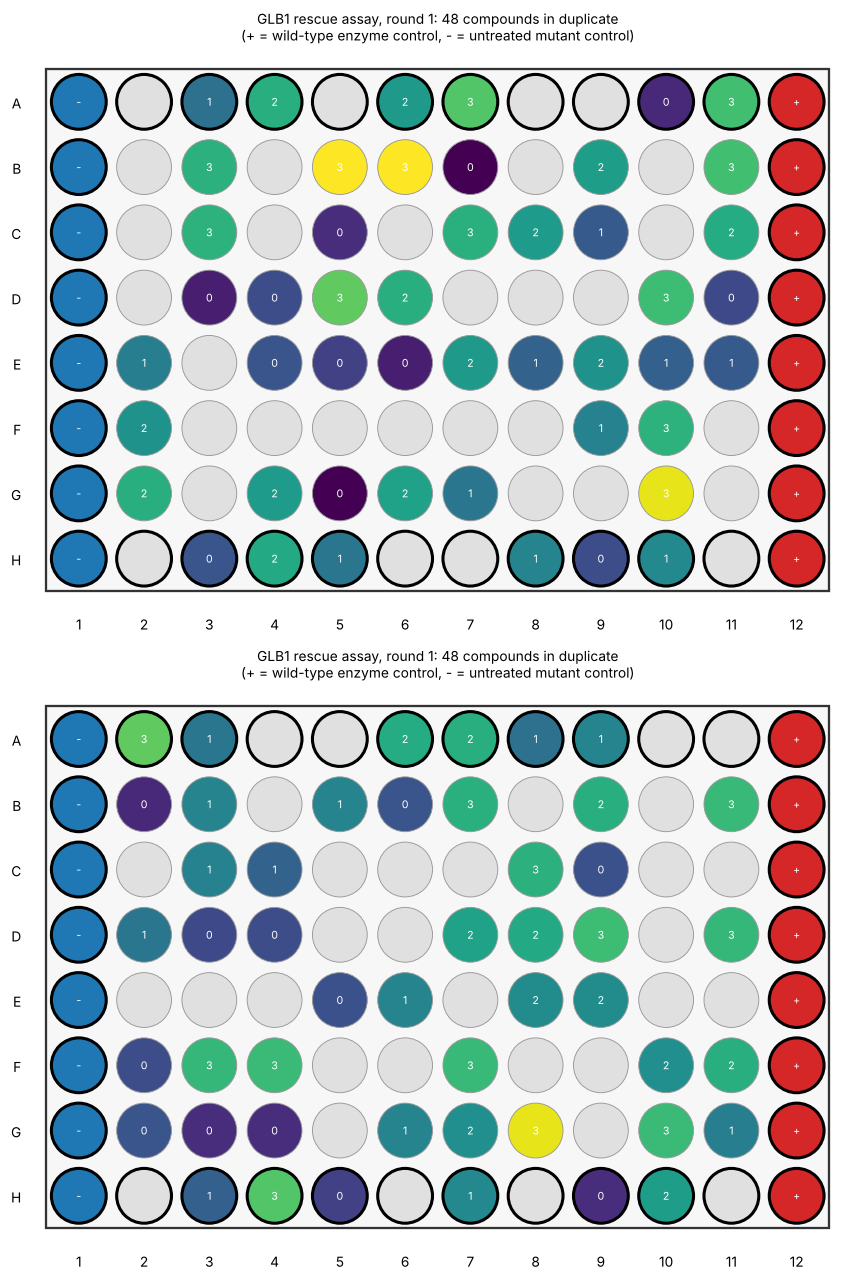

In [10]:
fig = render_plate_map(
    layout,
    title="GLB1 rescue assay, round 1: 48 compounds in duplicate\n"
          "(+ = wild-type enzyme control, - = untreated mutant control)",
)
fig.savefig(FIGDIR / "04_glb1_plate_map.png", dpi=150, bbox_inches="tight")

In [11]:
TABDIR.mkdir(parents=True, exist_ok=True)
batch.to_csv(str(TABDIR / "04_glb1_batch_round1.csv"))
layout.to_csv(str(TABDIR / "04_glb1_plate_map_round1.csv"))
print("wrote the batch and the plate map to results/tables/")

# Confirm the invariants that make the plate interpretable.
wells = layout.to_frame()
samples = wells[wells["content_type"] == "sample"]
print(f"\ncontrols intact on every plate: {layout.control_wells_intact()}")
print(f"sample wells: {len(samples)}; replicates per compound: "
      f"{sorted(samples.groupby('item_id').size().unique())}")
print(f"compounds whose replicates span >1 plate: "
      f"{(samples.groupby('item_id')['plate'].nunique() > 1).sum()} of 48")
print("top-stratum edge enrichment vs chance: "
      f"{layout.diagnostics['top_stratum_edge_enrichment']}")

wrote the batch and the plate map to results/tables/

controls intact on every plate: True
sample wells: 96; replicates per compound: [np.int64(2)]
compounds whose replicates span >1 plate: 30 of 48
top-stratum edge enrichment vs chance: 0.667


## Five rounds

We play the assay from the answer key. In a real campaign this is where you
wait three weeks.

In [12]:
for _ in range(5):
    if campaign.round_index > 0:
        batch = campaign.select()
    measured = {i: truth[i] for i in batch.frame["compound_id"]}
    campaign.observe(measured)
    rec = campaign.history[-1]
    print(f"round {rec.round_index + 1}: {rec.n_hits:>2} rescuers in "
          f"{rec.n_selected} compounds ({rec.n_hits / rec.n_selected:>5.1%}), "
          f"${rec.cost:,.0f}"
          + (f", alpha={rec.alpha:.2f}" if rec.alpha else ""))

round 1: 11 rescuers in 48 compounds (22.9%), $7,570, alpha=0.40
round 2: 16 rescuers in 48 compounds (33.3%), $10,711, alpha=0.53


round 3: 12 rescuers in 48 compounds (25.0%), $12,054, alpha=0.65
round 4:  9 rescuers in 48 compounds (18.8%), $7,735, alpha=0.78


round 5:  7 rescuers in 48 compounds (14.6%), $4,951, alpha=0.90


In [13]:
report = campaign.report(oracle_labels=truth)
print(report.summary())

5 round(s), 240 compounds measured, 55 hit(s).
Hit rate by round: R1=22.9%, R2=33.3%, R3=25.0%, R4=18.8%, R5=14.6%
Cumulative hits: [11, 27, 39, 48, 55]
Fraction of achievable hits found: 61.1%
Calibration error (ECE) 0.032 -> 0.129 (worsening).
Batch diversity (1.0 = two random pool members): R1=0.83, R2=0.47, R3=0.64, R4=0.91, R5=0.74
Hybrid alpha by round: R1=0.40, R2=0.53, R3=0.65, R4=0.78, R5=0.90
Regret is measured against an oracle that knows every label: 90 actives exist in the pool. This is only possible in a retrospective replay.


In [14]:
show = ["round", "n_selected", "n_hits", "hit_rate", "cumulative_hits",
        "cumulative_cost", "cost_per_hit", "ece", "batch_diversity", "alpha"]
report.frame[show].round(3)

,round,n_selected,n_hits,hit_rate,cumulative_hits,cumulative_cost,cost_per_hit,ece,batch_diversity,alpha
0,1,48,11,0.229,11,7570.45,688.223,0.032,0.827,0.400
1,2,48,16,0.333,27,18281.72,677.101,0.061,0.470,0.525
2,3,48,12,0.250,39,30336.01,777.846,0.071,0.643,0.650
3,4,48,9,0.188,48,38070.80,793.142,0.081,0.912,0.775
4,5,48,7,0.146,55,43021.48,782.209,0.129,0.736,0.900


`cost_per_hit` is the number a project leader will actually ask about. It
combines everything -- selection quality, replicate policy, plate overhead, and
the acquisition cost of the compounds the policy chose.

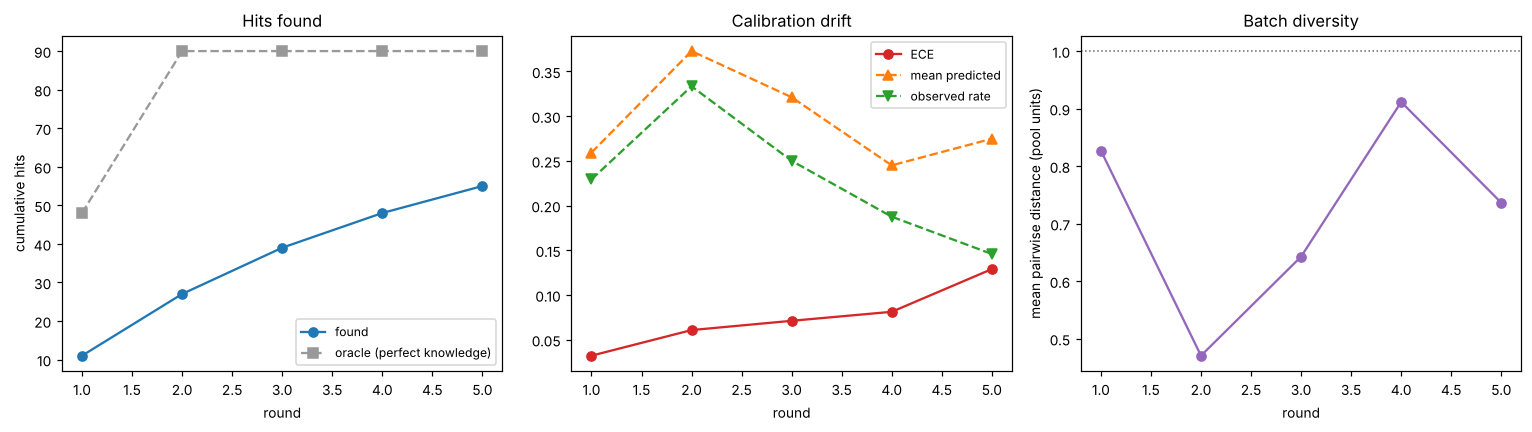

In [15]:
fig = report.plot()
fig.savefig(FIGDIR / "04_glb1_campaign_report.png", dpi=150, bbox_inches="tight")

## Pointing this at the real FoldRescue model

One line changes:

```python
from foldrescue import FoldRescueModel          # the real package

model = FoldRescueModel.load("glb1-chaperone-v2")
campaign = foldrescue_campaign(
    pool,
    model=model,                                 # <- the only change
    feature_cols=[...],                          # whatever FoldRescue consumes
    budget=96,
    policy="hybrid",
)
```

`FoldRescueAdapter` discovers how to sample from whatever it is given, so no
Loopwise code changes. Check `adapter.uncertainty_mode` after construction: if
it prints `point-estimate-only`, the model cannot express uncertainty and the
information-seeking policies will raise rather than silently degrade. Fix that
by giving the model a `sample()` method or by passing `n_bootstrap=12` with a
re-fittable model.

### Honest limitations of what you just ran

- The model and the pool are **simulated**. Real GLB1 chaperone chemistry is not
  a 24-dimensional Gaussian mixture.
- The assay is noiseless here. A real cell-based rescue assay has well-to-well
  variation comparable to the effect size, which is why the duplicate policy is
  on by default and why `replay_campaign(..., label_noise=...)` exists.
- Rescue in a cell line is not rescue in a patient. Chaperones that work in
  fibroblasts routinely fail on brain penetration, and that is a question no
  selection policy can answer.